In [14]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [16]:
data = load_breast_cancer()

X = data.data
y = data.target


In [17]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [18]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original Dimensions:", X.shape)
print("Reduced Dimensions:", X_pca.shape)

Original Dimensions: (569, 30)
Reduced Dimensions: (569, 2)


In [19]:
print("\n--- Explained Variance Ratio ---")
print(pca.explained_variance_ratio_)

total_variance = sum(pca.explained_variance_ratio_) * 100

print(
    f"Total Variance Explained by 2 Components: "
    f"{total_variance:.2f}%"
)


--- Explained Variance Ratio ---
[0.44272026 0.18971182]
Total Variance Explained by 2 Components: 63.24%


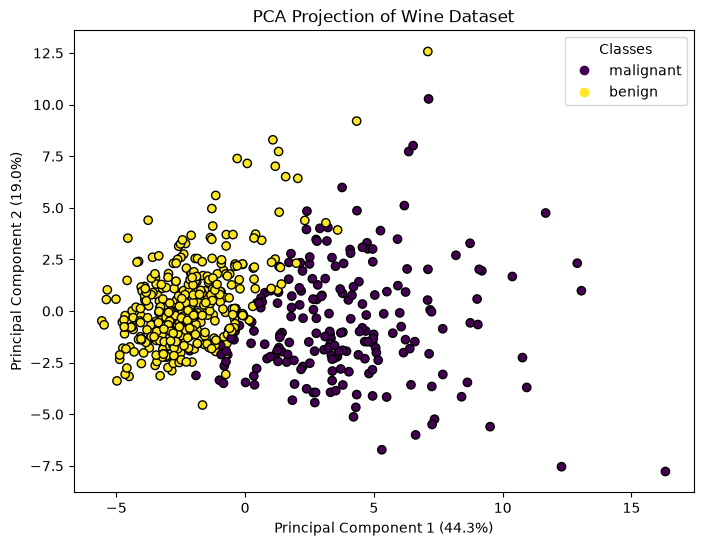

In [24]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    edgecolors="k"
)

# Axis Labels
plt.xlabel(
    f"Principal Component 1 "
    f"({pca.explained_variance_ratio_[0] * 100:.1f}%)"
)

plt.ylabel(
    f"Principal Component 2 "
    f"({pca.explained_variance_ratio_[1] * 100:.1f}%)"
)

plt.title("PCA Projection of Wine Dataset")

handles, _ = scatter.legend_elements()

plt.legend(
    handles,
    data.target_names,
    title="Classes"
)

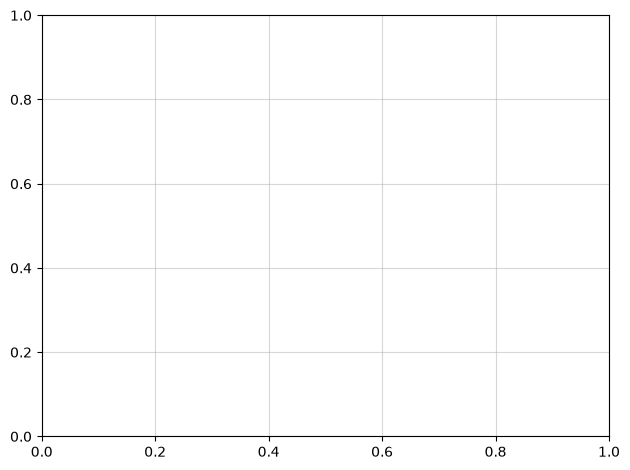

In [25]:
plt.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()